# 04 Classifier

Week 4 of *meter-trust*. Does a machine-learning model that combines all the signals do better than the three rules from notebook 03?

**Model.** scikit-learn `HistGradientBoostingClassifier`, one row per customer meter and 15-minute step, five classes. Features are computed only from the current and past steps, using only what an operator has: the readings, whether they arrived fresh, the transformer meter, and the outputs of the rule-based checks (WLS residuals, peer score, energy balance). The list is in `src/train.py`.

**Split by time, never at random.** Fit on episodes from days 0-14, choose the alarm threshold on days 15-20, test on days 21-27. A random split would put nearly identical neighbouring steps of the same episode on both sides and inflate the scores.

**Same false-alarm budget as the rules.** Trained with balanced class weights, the model flags far too many normal steps (about 17 % in a first try). It therefore raises an alarm only when P(not normal) passes a threshold set on days 15-20 to give 0.6 % false alarms, about what the rule-based detectors produce.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("pandapower").setLevel(logging.ERROR)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"
import numpy as np, pandas as pd
pd.set_option("display.precision", 3)
import scenarios as sc, detectors as det, evaluate as ev, train as tr, grid

In [2]:
# Regenerate anything missing (dataset ~1 min, WLS baseline ~6 min on 8 cores).
if not (sc.OUT_DIR / "labels.parquet").exists():
    sc.save(sc.generate())
data = sc.load()
wls_file = det.OUT_DIR / "wls.parquet"
if wls_file.exists():
    wls = pd.read_parquet(wls_file)
else:
    wls = det.run_wls_baseline(data)
    det.OUT_DIR.mkdir(parents=True, exist_ok=True); wls.to_parquet(wls_file)
out = det.run_all(data, wls=wls)
E, L = data["episodes"], data["labels"]

feat = tr.build_features(data, out)
model, threshold = tr.train(feat, E)
print(f"{len(feat):,} rows, {len(tr.FEATURES)} features; rows per part:",
      tr._part(feat, E).value_counts().to_dict())
print(f"alarm threshold P(not normal) > {threshold:.3f}; boosting iterations {model.n_iter_}")

1,123,200 rows, 14 features; rows per part: {'fit': 565344, 'test': 273312, 'calibrate': 239616, 'unused': 44928}
alarm threshold P(not normal) > 0.928; boosting iterations 67


In [3]:
test = E.index[E.split == "test"]
preds = {**out["pred"], "ml": tr.predict_frame(model, threshold, feat, L)}
names = {**ev.NAMES, "ml": "4. Gradient-boosted classifier"}
cms = {k: ev.confusion(L, p, test) for k, p in preds.items()}
fa = pd.Series({names[k]: ev.false_alarm_rate(L.loc[test], p.loc[test]) for k, p in preds.items()},
               name="false alarms on normal meter-steps (test)")
fa.to_frame()

,false alarms on normal meter-steps (test)
1. WLS + chi-square + LNR,0.001
2. Peer check,0.008
3. Peer check + energy balance,0.008
4. Gradient-boosted classifier,0.010


## Test weeks: confusion matrices (meter-steps, days 21-27)

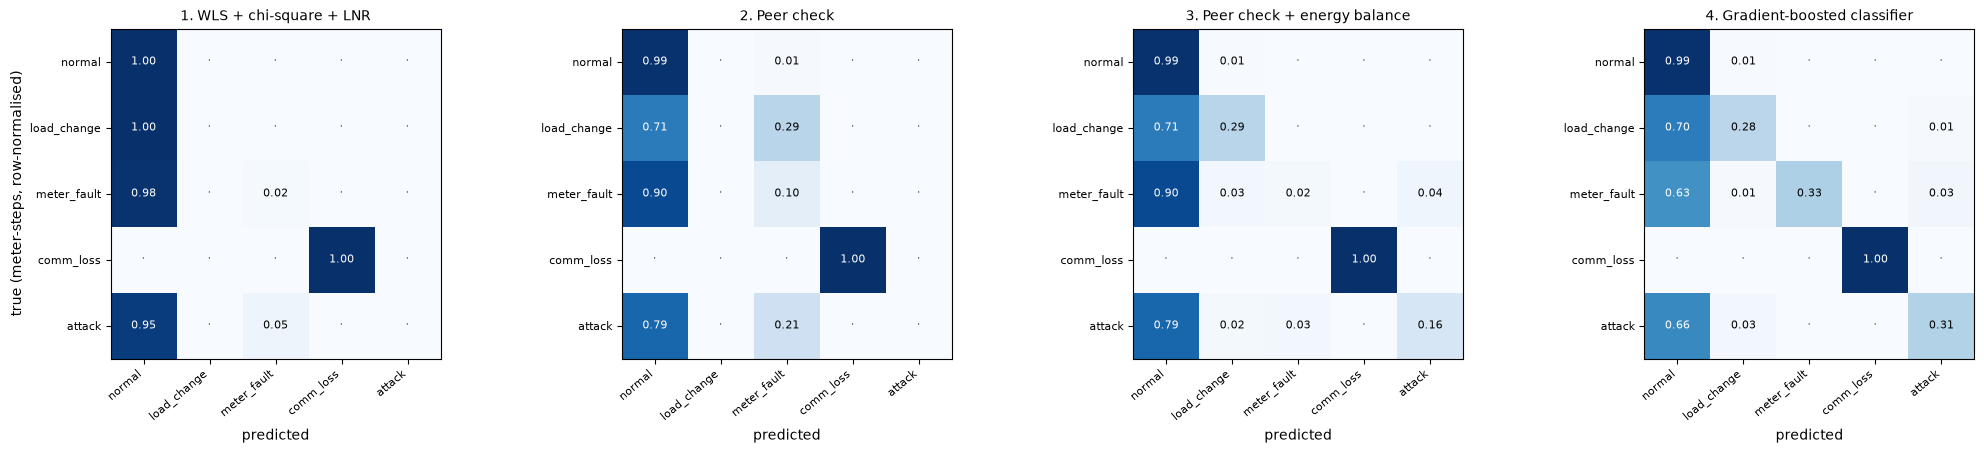

In [4]:
fig = ev.plot_confusions(cms, FIG / "confusion_matrices_test.png")
for ax, k in zip(fig.axes, cms): ax.set_title(names[k], fontsize=10)
fig.savefig(FIG / "confusion_matrices_test.png", dpi=150, bbox_inches="tight")

In [5]:
pd.concat({names[k]: ev.per_class(cm)[["precision", "recall"]] for k, cm in cms.items()}, axis=1)

1. WLS + chi-square + LNR        2. Peer check         \
                            precision recall     precision recall   
true                                                                
normal                          0.992  0.999         0.993  0.992   
load_change                       NaN  0.000           NaN  0.000   
meter_fault                     0.029  0.016         0.026  0.098   
comm_loss                       1.000  1.000         1.000  1.000   
attack                            NaN  0.000           NaN  0.000   

            3. Peer check + energy balance         \
                                 precision recall   
true                                                
normal                               0.993  0.992   
load_change                          0.098  0.290   
meter_fault                          0.130  0.023   
comm_loss                            1.000  1.000   
attack                               0.287  0.162   

            4. Gradient-boosted classifier         
                                 precision recall  
true                                               
normal                               0.994  0.990  
load_change                          0.116  0.283  
meter_fault                          0.385  0.328  
comm_loss                            1.000  1.000  
attack                               0.268  0.314

## Test weeks: per event

Share of test events where an affected meter was ever given the right class. There are only 5-8 test events per subtype, so one event moves a number by 12-20 points.

In [6]:
det_tab = pd.concat({names[k]: ev.detection(E.loc[test], p).groupby(["cls", "subtype"]).detected.mean()
                     for k, p in preds.items()}, axis=1)
det_tab.insert(0, "events", ev.detection(E.loc[test], preds["ml"]).groupby(["cls", "subtype"]).size())
det_tab.round(2)

events  1. WLS + chi-square + LNR  2. Peer check  \
cls         subtype                                                        
attack      consistent       7                        0.0            0.0   
            naive            7                        0.0            0.0   
comm_loss   dropout          5                        1.0            1.0   
            gateway          5                        1.0            1.0   
            stale            5                        1.0            1.0   
load_change down             6                        0.0            0.0   
            up               8                        0.0            0.0   
meter_fault drift            5                        0.0            0.0   
            gain             5                        0.2            0.6   
            stuck            5                        0.0            0.6   

                        3. Peer check + energy balance  \
cls         subtype                                      
attack      consistent                            0.43   
            naive                                 0.57   
comm_loss   dropout                               1.00   
            gateway                               1.00   
            stale                                 1.00   
load_change down                                  0.33   
            up                                    1.00   
meter_fault drift                                 0.00   
            gain                                  0.60   
            stuck                                 0.20   

                        4. Gradient-boosted classifier  
cls         subtype                                     
attack      consistent                            0.71  
            naive                                 0.57  
comm_loss   dropout                               1.00  
            gateway                               1.00  
            stale                                 1.00  
load_change down                                  1.00  
            up                                    0.88  
meter_fault drift                                 0.40  
            gain                                  0.60  
            stuck                                 1.00

**Chance level.** With about 1 % false alarms, a detector will sometimes give the right class to the right meter by luck. Below: how often each detector produces each class on a *random* meter in a normal test episode over the same kind of window. A detection rate means something only well above this.

In [7]:
pd.concat({names[k]: ev.chance_detection(E.loc[test], p) for k, p in preds.items()}, axis=1).round(2)

,1. WLS + chi-square + LNR,2. Peer check,3. Peer check + energy balance,4. Gradient-boosted classifier
load_change,0.00,0.00,0.07,0.27
meter_fault,0.07,0.07,0.00,0.13
comm_loss,0.00,0.00,0.00,0.00
attack,0.00,0.00,0.00,0.07


## What the classifier uses

Permutation importance on the test weeks: how much macro-F1 drops when one feature is shuffled.

,importance
fresh,0.228
peer_z,0.093
flatness_2h,0.079
balance_e,0.077
hour,0.023
p_kw,0.020
not_fresh_2h,0.011
wls_rn_max,0.007
wls_J,0.005
gateway_silent_share,0.003


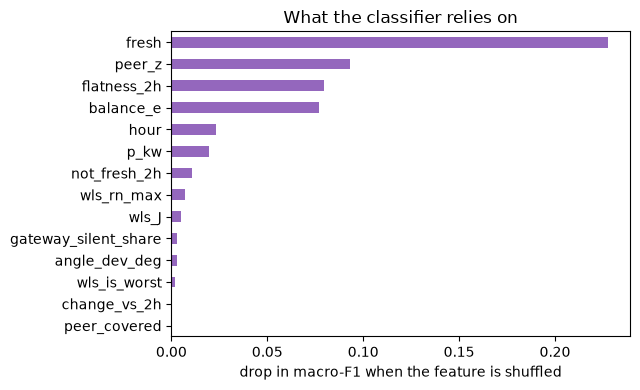

In [8]:
imp = tr.importance(model, feat)
ev.plot_importance(imp, FIG / "feature_importance.png")
imp.round(3).to_frame("importance")

## What this says

- **At the same false-alarm level the classifier beats every rule, but by less than the raw numbers suggest.** It names 5 of 7 consistent attacks in the test weeks (chance level 7 %) and every stuck meter. Its load-change score (88-100 %) is weaker evidence: it hands out `load_change` so freely that it would hit a random meter in about a quarter of normal episodes. When it does raise an alarm on a real load change, it rarely calls it an attack, and the reverse is also rare: the key confusion is small.
- **In plain words, it relies mostly on four things:** whether the reading arrived on time, how far the meter has drifted from its usual peers, whether the reading has gone flat, and whether the transformer total still adds up. The WLS residuals add almost nothing. That fits notebook 03: on this feeder the residual test only repeats what the transformer balance already says.
- **Meter-step recall is still modest** (roughly a third for faults, attacks and load changes): the model tends to notice an event a few steps late and not at every step. Slow drift remains the hardest case.
- **Caveats.** The test weeks hold 5-8 events per subtype, so the event-level numbers are rough. Chance-level hits are not zero. The model has learned the regularities of *this* simulator (one event per day, a fixed set of fault types), and would need real data before anyone should trust it.
- **Nothing here changes the main limit.** If the attacker could also edit the transformer reading, the faked readings would match a real load change everywhere, and no model trained on these measurements could separate them.